In [71]:
import numpy as np
import pandas as pd
import time
import re
import html
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from deep_translator import GoogleTranslator
from bs4 import BeautifulSoup, Comment, MarkupResemblesLocatorWarning
from scipy.stats import mannwhitneyu
import warnings
import pickle
from tqdm import tqdm
from tqdm.notebook import tqdm
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, accuracy_score, average_precision_score, f1_score, precision_recall_curve
from xgboost import XGBClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay
from itertools import combinations
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import confusion_matrix

### Load Dataset (with English translation)

In [21]:
# Load the clean dataset
pd.set_option('display.max_columns', None)
clean_data = pd.read_csv("all_data_with_english_translations.csv", usecols=['created_at', 'subdomain','table','label','is_spam','url_count','has_url','body_clean','language','body_english'])
clean_data['has_url'] = clean_data['has_url'].astype(int)
display(len(clean_data))
display(clean_data.head())

93323

,created_at,subdomain,table,is_spam,label,url_count,has_url,body_clean,language,body_english
0,2023-02-24 01:52:08,support,hc_answers,0,NaN,0,0,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.",en,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities."
1,2022-06-22 20:38:15,support,hc_comments,0,NaN,0,0,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.,en,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.
2,2022-11-04 14:14:18,support,hc_comments,0,NaN,0,0,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks,en,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks
3,2023-04-11 07:27:27,support,hc_answers,0,NaN,0,0,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!",en,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!"
4,2022-05-09 16:19:22,support,hc_answers,0,NaN,0,0,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?,en,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?


In [22]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option("display.max_colwidth", None)
display(len(clean_data[clean_data['label'] == 14]))

6

In [23]:
clean_data = clean_data[clean_data['label'] != 14].copy()

### Extract Features (Word Count)

In [24]:
#Add word count

clean_data['word_count'] = clean_data['body_english'].str.split().str.len()
display(clean_data.head())

,created_at,subdomain,table,is_spam,label,url_count,has_url,body_clean,language,body_english,word_count
0,2023-02-24 01:52:08,support,hc_answers,0,NaN,0,0,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.",en,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.",66.0
1,2022-06-22 20:38:15,support,hc_comments,0,NaN,0,0,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.,en,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.,38.0
2,2022-11-04 14:14:18,support,hc_comments,0,NaN,0,0,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks,en,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks,52.0
3,2023-04-11 07:27:27,support,hc_answers,0,NaN,0,0,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!",en,"Hi Rey,\n \nI created a ticket on your behalf and will send it to you via email so we can further discuss your concern regarding your report.\n \nThank you!",29.0
4,2022-05-09 16:19:22,support,hc_answers,0,NaN,0,0,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?,en,I too am trying to accomplish this but haven't been able to figure it out yet. If the ticket cannot be submitted by the end user can the form filler at least be CC'd on the ticket?,37.0


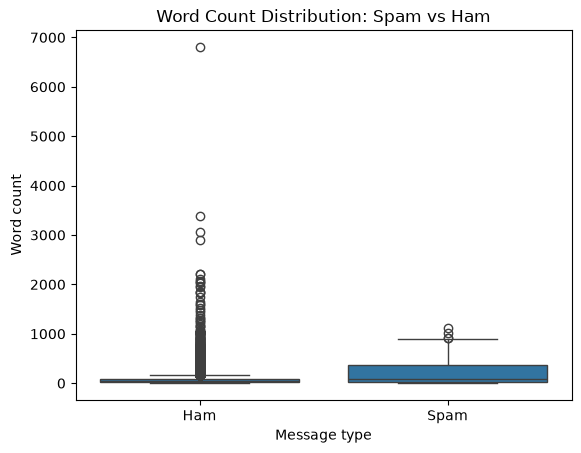

In [25]:
plot_data = clean_data.copy()

sns.boxplot(
    data=plot_data,
    x="is_spam",
    y="word_count"
)

plt.xticks([0, 1], ["Ham", "Spam"])
plt.xlabel("Message type")
plt.ylabel("Word count")
plt.title("Word Count Distribution: Spam vs Ham")
plt.show()

In [26]:
# Separate URL counts
ham_word_count = clean_data.loc[
    clean_data["is_spam"] == 0, "word_count"
].dropna()

spam_word_count= clean_data.loc[
    clean_data["is_spam"] == 1, "word_count"
].dropna()

# Mann-Whitney U test
stat, p_value = mannwhitneyu(
    spam_word_count,
    ham_word_count,
    alternative="greater"
)

# Sample sizes
n_spam = len(spam_word_count)
n_ham = len(ham_word_count)

# Medians
spam_median = spam_word_count.median()
ham_median = ham_word_count.median()

# Effect size: rank-biserial correlation
effect_size = (2 * stat / (n_spam * n_ham)) - 1

print("Spam sample size:", n_spam)
print("Ham sample size:", n_ham)

print("Spam median word count:", spam_median)
print("Ham median word count:", ham_median)

print("Mann-Whitney U statistic:", stat)
print(f"P-value: {p_value:.10e}")
print("Rank-biserial effect size:", effect_size)

if p_value < 0.05:
    print("Result: Spam messages tend to have significantly more word count.")
else:
    print("Result: No statistically significant evidence that spam messages tend to have more word count.")


Spam sample size: 4371
Ham sample size: 88885
Spam median word count: 82.0
Ham median word count: 47.0
Mann-Whitney U statistic: 251972946.5
P-value: 3.1421444645e-242
Rank-biserial effect size: 0.2971034872961005
Result: Spam messages tend to have significantly more word count.


In [61]:
numerical_cols = ['url_count', 'has_url', 'word_count']

display(clean_data[numerical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
url_count,93317.0,0.368936,1.587079,0.0,0.0,0.0,0.0,113.0
has_url,93317.0,0.194584,0.395882,0.0,0.0,0.0,0.0,1.0
word_count,93256.0,72.186240,98.495265,1.0,26.0,48.0,83.0,6803.0


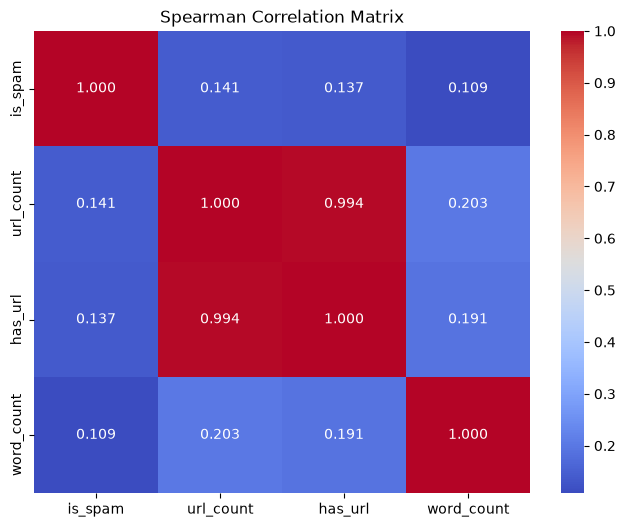

In [62]:
correlation = clean_data[
    ['is_spam', 'url_count', 'has_url', 'word_count']
].corr(method='spearman')

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.3f'
)

plt.title('Spearman Correlation Matrix')
plt.show()

In [68]:
# Contingency table
url_spam_table = pd.crosstab(
    clean_data['has_url'],
    clean_data['is_spam']
)

# Convert counts to percentages within each URL group
url_spam_percentage = (
    url_spam_table
    .div(url_spam_table.sum(axis=1), axis=0) * 100
)

# Rename columns and index
url_spam_table.columns = ['HAM', 'SPAM']
url_spam_percentage.columns = ['HAM (%)', 'SPAM (%)']

url_spam_table.index = ['No URL', 'Has URL']
url_spam_percentage.index = ['No URL', 'Has URL']

print("Email counts:")
display(url_spam_table)

print("Email percentages:")
display(
    url_spam_percentage.style
    .format('{:.2f}%')
    .background_gradient(cmap='Blues')
)

Email counts:


,HAM,SPAM
No URL,72698,2461
Has URL,16237,1921


Email percentages:


,HAM (%),SPAM (%)
No URL,96.73%,3.27%
Has URL,89.42%,10.58%


#### Chi-square test of independence

In [ ]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    clean_data['has_url'],
    clean_data['is_spam']
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

n = contingency_table.to_numpy().sum()
r, k = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, k - 1))
)

# Create results table
results_df = pd.DataFrame({
    'Statistic': [
        'Chi-square',
        'Degrees of Freedom',
        'P-value',
        "Cramér's V"
    ],
    'Value': [
        chi2,
        dof,
        p_value,
        cramers_v
    ]
})

# Display formatted table
styled_results = (
    results_df.style
    .format({
        'Value': lambda x: (
            f'{x:.6e}' if x < 0.0001
            else f'{x:.4f}'
        )
    })
    .set_caption(
        'Chi-square Test and Cramér\'s V Results'
    )
    .set_properties(**{
        'text-align': 'center',
        'font-size': '12pt'
    })
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('text-align', 'center'),
                ('background-color', '#e8eef7'),
                ('font-size', '12pt')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('font-size', '14pt'),
                ('font-weight', 'bold'),
                ('text-align', 'center')
            ]
        }
    ])
)

display(styled_results)


,Statistic,Value
0,Chi-square,1742.1865
1,Degrees of Freedom,1.0000
2,P-value,0.000000e+00
3,Cramér's V,0.1366


is_spam,0,1
has_url,,
0,"72,698","2,461"
1,"16,237","1,921"


### Model Building

In [27]:
# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'word_count']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])  # Features for the model
y = clean_data_filtered['is_spam']                 # What you want to predict

print("--- Features (X) ---")
display(X.head())

print("\n--- Target / Prediction (y) ---")
display(y.head())

print(len(X))
print(len(y))

--- Features (X) ---


,url_count,has_url,word_count
0,0,0,66.0
1,0,0,38.0
2,0,0,52.0
3,0,0,29.0
4,0,0,37.0



--- Target / Prediction (y) ---


0    0
1    0
2    0
3    0
4    0
Name: is_spam, dtype: int64

93317
93317


### Individual Features

In [28]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, f1_score
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Ensure your target and features are isolated and NaNs are filled with 0
features = ['url_count', 'has_url', 'word_count']
X = clean_data[features].fillna(0)
y = clean_data['is_spam']

# ==========================================
# 1. DYNAMIC INDIVIDUAL FEATURE EVALUATION
# ==========================================
feature_results = []

for feature in features:
    X_single = X[[feature]]

    X_train, X_test, y_train, y_test = train_test_split(
        X_single, y, test_size=0.2, random_state=42, stratify=y
    )

    neg_count = (y_train == 0).sum()
    pos_count = (y_train == 1).sum()
    weight_ratio = neg_count / pos_count if pos_count > 0 else 1.0

    model = XGBClassifier(scale_pos_weight=weight_ratio, random_state=42, eval_metric='logloss')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Extract metrics for the spam class (class 1)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average=None)
    
    feature_results.append({
        'Feature': feature,
        'Spam Precision': precision[1],
        'Spam Recall': recall[1],
        'Spam F1-Score': f1[1]
    })

df_features = pd.DataFrame(feature_results)
print("--- Individual Feature Performance ---")
display(df_features.style.format({
    'Spam Precision': '{:.4f}',
    'Spam Recall': '{:.4f}',
    'Spam F1-Score': '{:.4f}'
}).hide(axis='index'))

--- Individual Feature Performance ---


Feature,Spam Precision,Spam Recall,Spam F1-Score
url_count,0.1089,0.4532,0.1756
has_url,0.1092,0.4543,0.1760
word_count,0.1147,0.4932,0.1861


### Features (URL Count, Has URL, Word Count)

In [29]:
# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'word_count']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])  # Features for the model
y = clean_data_filtered['is_spam']                 # What you want to predict

# 2. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 1. Calculate the ratio of non-spam (0) to spam (1) in your training set
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
weight_ratio = neg_count / pos_count

print(f"Non-spam count: {neg_count}, Spam count: {pos_count}")
print(f"Recommended scale_pos_weight: {weight_ratio:.2f}")

# 2. Re-initialize XGBoost with the scale_pos_weight parameter
model = XGBClassifier(
    scale_pos_weight=weight_ratio, # <-- This forces it to care about spam
    random_state=42,
    eval_metric='logloss'
)

# 3. Retrain the model
model.fit(X_train, y_train)

# 4. Evaluate again
y_pred = model.predict(X_test)
print("\nNew Classification Report:\n", classification_report(y_test, y_pred))

Non-spam count: 71147, Spam count: 3506
Recommended scale_pos_weight: 20.29

New Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.80      0.88     17788
           1       0.14      0.66      0.23       876

    accuracy                           0.79     18664
   macro avg       0.56      0.73      0.55     18664
weighted avg       0.94      0.79      0.85     18664



In [30]:
model = XGBClassifier(
    scale_pos_weight=8.0, # <-- This forces it to care about spam
    random_state=42,
    eval_metric='logloss'
)

# 3. Retrain the model
model.fit(X_train, y_train)

# 4. Evaluate again
y_pred = model.predict(X_test)
print("\nNew Classification Report:\n", classification_report(y_test, y_pred))


New Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.95      0.96     17788
           1       0.29      0.41      0.34       876

    accuracy                           0.92     18664
   macro avg       0.63      0.68      0.65     18664
weighted avg       0.94      0.92      0.93     18664



In [31]:
# 3. Get probabilities instead of default 0/1 predictions
# predict_proba returns columns for [prob_of_not_spam, prob_of_spam]
# We take [:, 1] to get specifically the probability of being spam
y_probs = model.predict_proba(X_test)[:, 1]

# 4. Apply your custom threshold (e.g., 80% certainty required to label as spam)
custom_threshold = 0.6
y_pred_custom = (y_probs >= custom_threshold).astype(int)

# 5. Evaluate the results with your custom threshold
print(f"Accuracy (at threshold {custom_threshold}): {accuracy_score(y_test, y_pred_custom):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_custom))

Accuracy (at threshold 0.6): 0.9509

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.97     17788
           1       0.47      0.33      0.39       876

    accuracy                           0.95     18664
   macro avg       0.72      0.66      0.68     18664
weighted avg       0.94      0.95      0.95     18664



### Only TF-IDF Features

In [ ]:
# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'body_english']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])  # Features for the model
y = clean_data_filtered['is_spam']                 # What you want to predict

# FIX: Replace NaN values with an empty string and ensure everything is a string
X['body_english'] = X['body_english'].fillna('').astype(str)

# 2. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Apply TF-IDF to the cleaned text body
# max_features=5000 keeps the top 5,000 most important words/phrases
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_text = vectorizer.fit_transform(X_train['body_english'])
X_test_text = vectorizer.transform(X_test['body_english'])

# 4. Extract numerical features
#X_train_num = X_train[['url_count', 'has_url', 'word_count']].astype(np.float32).values
#X_test_num = X_test[['url_count', 'has_url', 'word_count']].astype(np.float32).values

# 5. Combine numerical features and TF-IDF text features into a single sparse matrix
X_train_combined = hstack([X_train_text])
X_test_combined = hstack([X_test_text])

# 6. Initialize XGBoost 
# Note: Lowered scale_pos_weight from 20.27 to 5.0 to prevent severe false positives.
model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=5.0,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    max_bin=128,
    n_jobs=2
)

# 7. Train the model
model.fit(X_train_combined, y_train)

# 8. Predict probabilities (needed for PR-AUC)
y_pred_proba = model.predict_proba(X_test_combined)[:, 1]

# 9. Calculate PR-AUC (Average Precision Score is standard for summarizing PR curve)
pr_auc = average_precision_score(y_test, y_pred_proba)
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")

# 10. Evaluate with default 0.5 threshold
y_pred = model.predict(X_test_combined)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

PR-AUC (Average Precision): 0.9608

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99     17788
           1       0.79      0.95      0.86       876

    accuracy                           0.99     18664
   macro avg       0.89      0.97      0.93     18664
weighted avg       0.99      0.99      0.99     18664



### Numerical + TF-IDF Features

In [33]:
# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'word_count', 'body_english']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])  # Features for the model
y = clean_data_filtered['is_spam']                 # What you want to predict

# FIX: Replace NaN values with an empty string and ensure everything is a string
X['body_english'] = X['body_english'].fillna('').astype(str)

# 2. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Apply TF-IDF to the cleaned text body
# max_features=5000 keeps the top 5,000 most important words/phrases
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_text = vectorizer.fit_transform(X_train['body_english'])
X_test_text = vectorizer.transform(X_test['body_english'])

# 4. Extract numerical features
X_train_num = X_train[['url_count', 'has_url', 'word_count']].astype(np.float32).values
X_test_num = X_test[['url_count', 'has_url', 'word_count']].astype(np.float32).values

# 5. Combine numerical features and TF-IDF text features into a single sparse matrix
X_train_combined = hstack([X_train_num, X_train_text])
X_test_combined = hstack([X_test_num, X_test_text])

# 6. Initialize XGBoost 
# Note: Lowered scale_pos_weight from 20.27 to 5.0 to prevent severe false positives.
model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=5.0,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    max_bin=128,
    n_jobs=2
)

# 7. Train the model
model.fit(X_train_combined, y_train)

# 8. Predict probabilities (needed for PR-AUC)
y_pred_proba = model.predict_proba(X_test_combined)[:, 1]

# 9. Calculate PR-AUC (Average Precision Score is standard for summarizing PR curve)
pr_auc = average_precision_score(y_test, y_pred_proba)
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")

# 10. Evaluate with default 0.5 threshold
y_pred = model.predict(X_test_combined)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

PR-AUC (Average Precision): 0.9745

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     17788
           1       0.91      0.92      0.92       876

    accuracy                           0.99     18664
   macro avg       0.95      0.96      0.96     18664
weighted avg       0.99      0.99      0.99     18664



### Compute Embeddings

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, average_precision_score
from scipy.sparse import hstack, csr_matrix
from sentence_transformers import SentenceTransformer
from xgboost import XGBClassifier
import pandas as pd

# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'word_count', 'body_english']
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam']) 
y = clean_data_filtered['is_spam'] 

# FIX: Replace NaN values with an empty string and ensure everything is a string
X['body_english'] = X['body_english'].fillna('').astype(str)

# 3. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Apply TF-IDF to the text body
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_text = vectorizer.fit_transform(X_train['body_english'])
X_test_text = vectorizer.transform(X_test['body_english'])

# 5. Generate Text Embeddings using a lightweight, fast transformer model
print("Generating text embeddings...")
embedder = SentenceTransformer('all-MiniLM-L6-v2')
X_train_emb = embedder.encode(X_train['body_english'].tolist(), show_progress_bar=True)
X_test_emb = embedder.encode(X_test['body_english'].tolist(), show_progress_bar=True)

# 6. Extract numerical features
X_train_num = X_train[['url_count', 'has_url', 'word_count']].values
X_test_num = X_test[['url_count', 'has_url', 'word_count']].values




Generating text embeddings...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/2333 [00:00<?, ?it/s]

Batches:   0%|          | 0/584 [00:00<?, ?it/s]

### Only Embeddings

In [35]:
# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'body_english']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])  # Features for the model
y = clean_data_filtered['is_spam']                 # What you want to predict

# FIX: Replace NaN values with an empty string and ensure everything is a string
X['body_english'] = X['body_english'].fillna('').astype(str)

# 2. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Apply TF-IDF to the cleaned text body
# max_features=5000 keeps the top 5,000 most important words/phrases
X_train_combined = hstack([csr_matrix(X_train_emb)])
X_test_combined = hstack([csr_matrix(X_test_emb)])

# 6. Initialize XGBoost 
# Note: Lowered scale_pos_weight from 20.27 to 5.0 to prevent severe false positives.
model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=5.0,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    max_bin=128,
    n_jobs=2
)

# 7. Train the model
model.fit(X_train_combined, y_train)

# 8. Predict probabilities (needed for PR-AUC)
y_pred_proba = model.predict_proba(X_test_combined)[:, 1]

# 9. Calculate PR-AUC (Average Precision Score is standard for summarizing PR curve)
pr_auc = average_precision_score(y_test, y_pred_proba)
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")

# 10. Evaluate with default 0.5 threshold
y_pred = model.predict(X_test_combined)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

PR-AUC (Average Precision): 0.9583

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00     17788
           1       0.90      0.90      0.90       876

    accuracy                           0.99     18664
   macro avg       0.95      0.95      0.95     18664
weighted avg       0.99      0.99      0.99     18664



### Numerical + TF-IDF + Embeddings

In [60]:

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix

from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
)

from xgboost import XGBClassifier


# --------------------------------------------------
# 1. Clean sparse matrices
# --------------------------------------------------

def clean_sparse_matrix(matrix):
    mat_csr = csr_matrix(matrix, dtype=np.float64)
    mat_csr.data = np.nan_to_num(
        mat_csr.data,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )
    return mat_csr

#Scale numerical features
scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

# Combine numerical, TF-IDF, and embedding features into a single sparse matrix
# We convert the dense embedding arrays to sparse matrices for memory efficiency
X_train_combined = hstack([
    csr_matrix(X_train_num_scaled), 
    X_train_text, 
    csr_matrix(X_train_emb)
]).tocsr()
X_test_combined = hstack([
    csr_matrix(X_test_num_scaled), 
    X_test_text, 
    csr_matrix(X_test_emb)
]).tocsr()

X_train_clean = clean_sparse_matrix(X_train_combined)
X_test_clean = clean_sparse_matrix(X_test_combined)

# Check feature values
print("Minimum feature value:", X_train_clean.data.min())
print("Maximum feature value:", X_train_clean.data.max())


# --------------------------------------------------
# 2. Calculate class imbalance
# --------------------------------------------------

negative_count = np.sum(np.asarray(y_train) == 0)
positive_count = np.sum(np.asarray(y_train) == 1)

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Scale positive weight:", scale_pos_weight)


# --------------------------------------------------
# 3. Define models
# --------------------------------------------------

models = {
    "Linear SVM": CalibratedClassifierCV(
        LinearSVC(
            class_weight="balanced",
            random_state=42
        ),
        cv=3
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=500,
            max_depth=3,
            learning_rate=0.1,
            scale_pos_weight=5.0,
            random_state=42,
            eval_metric='logloss',
            tree_method='hist',
            max_bin=128,
            n_jobs=2
    ),
}


# --------------------------------------------------
# 4. Train models and evaluate
# --------------------------------------------------

results = {}
trained_models = {}

custom_threshold = 0.5

for name, model in models.items():

    print(f"\n--- Training {name} ---")

    # Train
    model.fit(X_train_clean, y_train)

    trained_models[name] = model

    # Predict probabilities
    y_pred_proba = model.predict_proba(
        X_test_clean
    )[:, 1]

    # Apply threshold
    y_pred_custom = (
        y_pred_proba >= custom_threshold
    ).astype(int)

    cm = confusion_matrix(y_test, y_pred_custom)
    tn, fp, fn, tp = cm.ravel()

    # False Positive Rate = FP / (FP + TN)
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    # Classification report
    report = classification_report(
        y_test,
        y_pred_custom,
        output_dict=True,
        zero_division=0
    )

    # Metrics
    accuracy = accuracy_score(
        y_test,
        y_pred_custom
    )

    pr_auc = average_precision_score(
        y_test,
        y_pred_proba
    )

    results[name] = {
        "Accuracy": accuracy,
        "PR-AUC": pr_auc,
        "False Positive Rate (FPR)": fpr,

        "Precision (Class 0)": report["0"]["precision"],
        "Recall (Class 0)": report["0"]["recall"],
        "F1 (Class 0)": report["0"]["f1-score"],

        "Precision (Class 1)": report["1"]["precision"],
        "Recall (Class 1)": report["1"]["recall"],
        "F1 (Class 1)": report["1"]["f1-score"],

        "Macro F1": report["macro avg"]["f1-score"],
        "Weighted F1": report["weighted avg"]["f1-score"],
    }

    print(
        f"{name} Accuracy: {accuracy:.4f}"
    )

    print(
        classification_report(
            y_test,
            y_pred_custom,
            zero_division=0
        )
    )

    print(
        f"{name} PR-AUC: {pr_auc:.4f}"
    )


# --------------------------------------------------
# 5. Build comparison DataFrame
# --------------------------------------------------

summary_df = pd.DataFrame(results).T

summary_df = summary_df.sort_values(
    by="PR-AUC",
    ascending=False
)

cols_order = [
    "Accuracy",
    "PR-AUC",
    "False Positive Rate (FPR)",
    "Precision (Class 0)",
    "Recall (Class 0)",
    "F1 (Class 0)",
    "Precision (Class 1)",
    "Recall (Class 1)",
    "F1 (Class 1)",
    "Macro F1",
    "Weighted F1",
]

summary_df = summary_df[cols_order]


Minimum feature value: -0.7170177698135376
Maximum feature value: 70.35456085205078
Negative samples: 71147
Positive samples: 3506
Scale positive weight: 20.292926411865373

--- Training Linear SVM ---
Linear SVM Accuracy: 0.9953
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17788
           1       0.95      0.95      0.95       876

    accuracy                           1.00     18664
   macro avg       0.98      0.97      0.97     18664
weighted avg       1.00      1.00      1.00     18664

Linear SVM PR-AUC: 0.9877

--- Training Logistic Regression ---
Logistic Regression Accuracy: 0.9893
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     17788
           1       0.82      0.98      0.90       876

    accuracy                           0.99     18664
   macro avg       0.91      0.99      0.95     18664
weighted avg       0.99      0.99      0.99     18664

Logistic Regres

In [59]:
# --------------------------------------------------
# 6. Display styled comparison table
# --------------------------------------------------

styled_summary = (
    summary_df.style
    .background_gradient(
        cmap="Blues",
        subset=[
            col for col in summary_df.columns
            if col != "False Positive Rate (FPR)"
        ]
    )
    .background_gradient(
        cmap="Blues_r",
        subset=["False Positive Rate (FPR)"]
    )
    .format("{:.4f}")
    .set_caption(
        "Comprehensive Model Performance Comparison"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("font-size", "12pt"),
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("font-size", "11pt"),
                ("text-align", "center"),
            ],
        },
    ])
)

display(styled_summary)

,Accuracy,PR-AUC,False Positive Rate (FPR),Precision (Class 0),Recall (Class 0),F1 (Class 0),Precision (Class 1),Recall (Class 1),F1 (Class 1),Macro F1,Weighted F1
XGBoost,0.9946,0.9892,0.0035,0.9978,0.9965,0.9972,0.9310,0.9555,0.9431,0.9701,0.9946
Linear SVM,0.9953,0.9877,0.0022,0.9973,0.9978,0.9975,0.9539,0.9452,0.9495,0.9735,0.9953
Logistic Regression,0.9896,0.9863,0.0100,0.9990,0.9900,0.9945,0.8284,0.9806,0.8981,0.9463,0.9900
Random Forest,0.9862,0.9690,0.0008,0.9865,0.9992,0.9928,0.9769,0.7226,0.8307,0.9118,0.9852


In [55]:
print("Current training matrix:", X_train_clean.shape)
print("Current testing matrix:", X_test_clean.shape)

print("TF-IDF training matrix:", X_train_text.shape)
print("Numerical training matrix:", X_train_num.shape)

print("Embedding training matrix:", X_train_emb.shape)
print("Combined training matrix:", X_train_combined.shape)

Current training matrix: (74653, 5387)
Current testing matrix: (18664, 5387)
TF-IDF training matrix: (74653, 5000)
Numerical training matrix: (74653, 3)
Embedding training matrix: (74653, 384)
Combined training matrix: (74653, 5387)


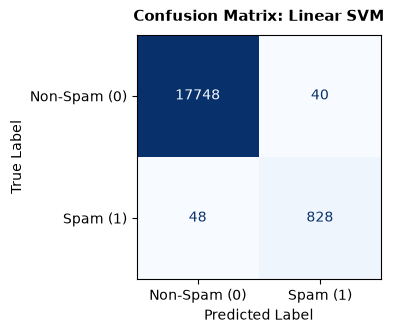

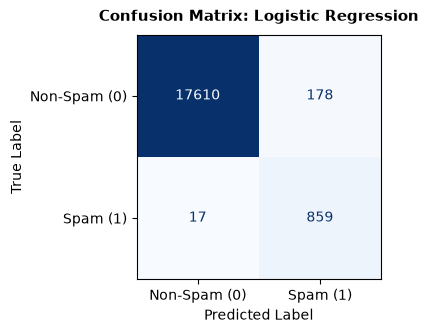

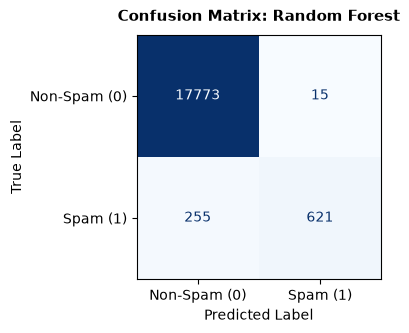

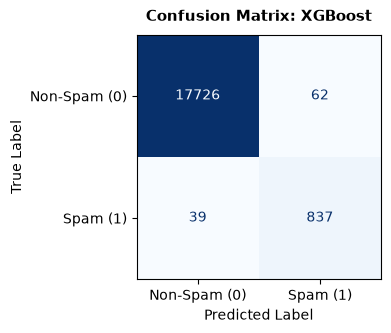

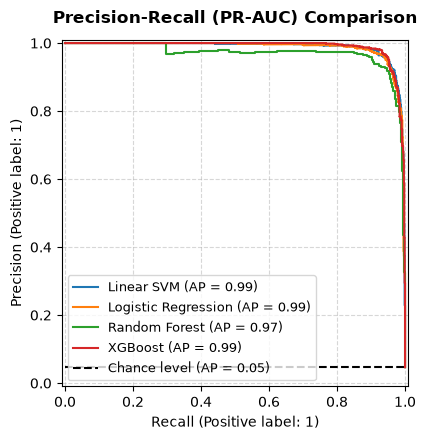

In [56]:
# ---------------------------------------------------------
# 4. Plotting Smaller Confusion Matrices for Each Model
# ---------------------------------------------------------
for name, trained_model in trained_models.items():
    fig, ax = plt.subplots(figsize=(4, 4))
    
    ConfusionMatrixDisplay.from_estimator(
        trained_model, 
        X_test_clean, 
        y_test, 
        display_labels=['Non-Spam (0)', 'Spam (1)'],
        cmap='Blues',
        ax=ax,
        colorbar=False
    )
    
    ax.set_title(f"Confusion Matrix: {name}", fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10)
    ax.set_ylabel("True Label", fontsize=10)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 5. Plotting a Compact Combined PR-AUC Curve
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 4.5))

for name, trained_model in trained_models.items():
    PrecisionRecallDisplay.from_estimator(
        trained_model, 
        X_test_clean, 
        y_test, 
        name=name,
        ax=ax,
        plot_chance_level=(name == "XGBoost")
    )

ax.set_title("Precision-Recall (PR-AUC) Comparison", fontsize=12, fontweight='bold', pad=12)
ax.legend(loc="lower left", fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [57]:
from sklearn.metrics import confusion_matrix

# 1. Compute the confusion matrix
# y_test: true labels (0 = Legitimate, 1 = Spam)
# y_pred: predicted labels from your model
cm = confusion_matrix(y_test, y_pred)

# Extract values from the confusion matrix
# [[TN, FP],
#  [FN, TP]]
tn, fp, fn, tp = cm.ravel()

# 2. Calculate False Positive Rate
fpr = fp / (fp + tn)

print(f"True Negatives (Correctly identified Legitimate): {tn}")
print(f"False Positives (Legitimate flagged as Spam): {fp}")
print(f"False Negative Rate (FNR): {fn / (fn + tp):.4f}")
print(f"False Positive Rate (FPR): {fpr:.4f} ({fpr * 100:.2f}%)")

True Negatives (Correctly identified Legitimate): 17697
False Positives (Legitimate flagged as Spam): 91
False Negative Rate (FNR): 0.0982
False Positive Rate (FPR): 0.0051 (0.51%)


PR-AUC (Average Precision): 0.9745

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     17788
           1       0.91      0.92      0.92       876

    accuracy                           0.99     18664
   macro avg       0.95      0.96      0.96     18664
weighted avg       0.99      0.99      0.99     18664



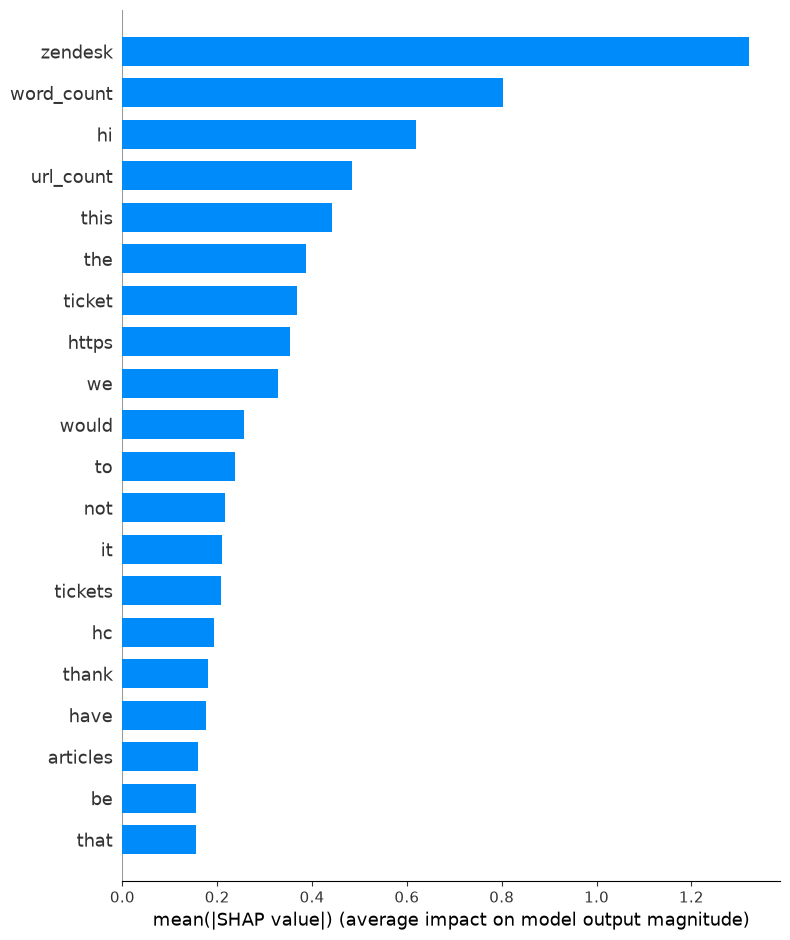

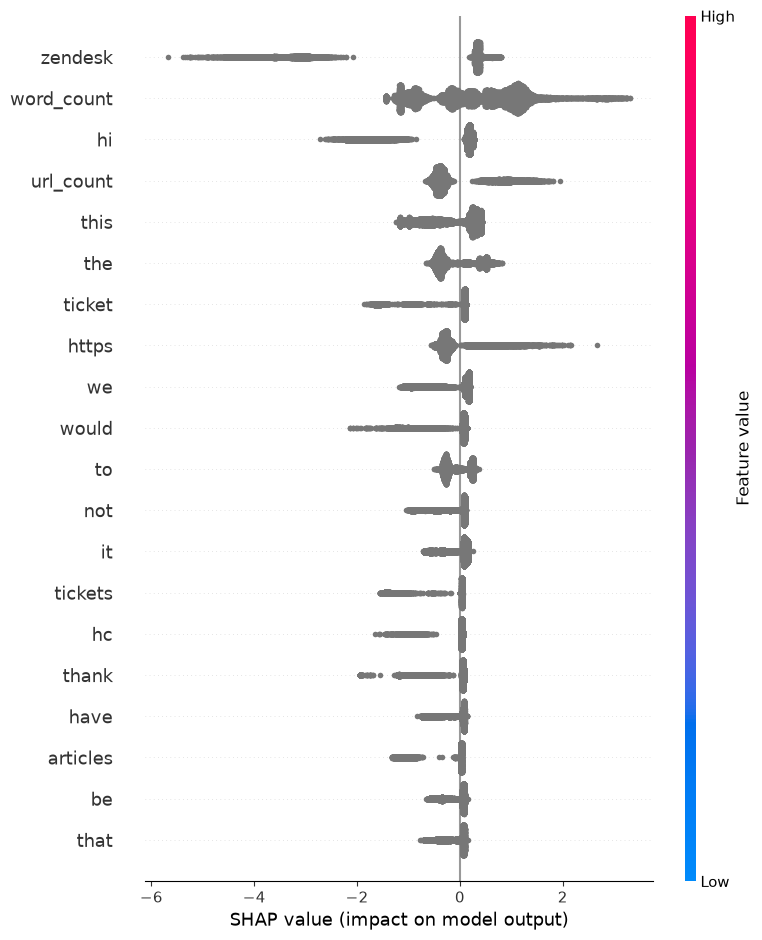

In [58]:
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.metrics import average_precision_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from xgboost import XGBClassifier
import shap

# 1. Define the exact columns you want to select
selected_cols = ['is_spam', 'url_count', 'has_url', 'word_count', 'body_english']

# Subset the DataFrame to only these columns
clean_data_filtered = clean_data[selected_cols]

# 2. Separate into features (X) and target prediction (y)
X = clean_data_filtered.drop(columns=['is_spam'])
y = clean_data_filtered['is_spam']

# Fix: Replace NaN values with an empty string and ensure everything is a string
X['body_english'] = X['body_english'].fillna('').astype(str)

# 3. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Apply TF-IDF to the cleaned text body
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_text = vectorizer.fit_transform(X_train['body_english'])
X_test_text = vectorizer.transform(X_test['body_english'])

# List of numerical feature columns used
num_cols = ['url_count', 'has_url', 'word_count']

# 5. Extract numerical features
X_train_num = X_train[num_cols].astype(np.float32).values
X_test_num = X_test[num_cols].astype(np.float32).values

# 6. Combine numerical features and TF-IDF text features into a single sparse matrix
X_train_combined = hstack([X_train_num, X_train_text]).tocsr()
X_test_combined = hstack([X_test_num, X_test_text]).tocsr()

# 7. Initialize and train XGBoost
model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=5.0,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    max_bin=128,
    n_jobs=2,
)

model.fit(X_train_combined, y_train)

# 8. Evaluation
y_pred_proba = model.predict_proba(X_test_combined)[:, 1]
pr_auc = average_precision_score(y_test, y_pred_proba)
print(f'PR-AUC (Average Precision): {pr_auc:.4f}')

y_pred = model.predict(X_test_combined)
print('\nClassification Report:\n', classification_report(y_test, y_pred))

# ==========================================
# 9. SHAP Feature Interpretability Setup
# ==========================================
# Generate full feature names list matching your combined matrix columns
feature_names = num_cols + list(vectorizer.get_feature_names_out())

# TreeExplainer works natively and efficiently with XGBoost
explainer = shap.TreeExplainer(model)

# Compute SHAP values on a test subset (e.g., first 1000 samples for speed)
#sample_size = min(1000, X_test_combined.shape[0])
#X_test_sample = X_test_combined[:sample_size]

shap_values = explainer(X_test_combined)

# 1. Global Feature Importance Bar Plot (Top 20 features across all test data)
shap.summary_plot(
    shap_values,
    X_test_combined,
    feature_names=feature_names,
    plot_type='bar',
    max_display=20,
)

# 2. Beeswarm Plot (Shows distribution of positive/negative impact for top features)
shap.summary_plot(
    shap_values, X_test_combined, feature_names=feature_names, max_display=20
)

In [72]:
# --------------------------------------------------
# 1. Generate predictions
# --------------------------------------------------

predictions = {}

for name, model in trained_models.items():

    y_pred_proba = model.predict_proba(
        X_test_clean
    )[:, 1]

    predictions[name] = (
        y_pred_proba >= custom_threshold
    ).astype(int)

print("Predictions generated for:")

for name in predictions:
    print(name)

# --------------------------------------------------
# 2. Pairwise McNemar's Test
# --------------------------------------------------

y_true = np.asarray(y_test)

model_pairs = list(
    combinations(predictions.keys(), 2)
)

mcnemar_results = []

for model_a, model_b in model_pairs:

    pred_a = predictions[model_a]
    pred_b = predictions[model_b]

    # Check whether each model predicted correctly
    correct_a = pred_a == y_true
    correct_b = pred_b == y_true

    # Discordant pairs
    # Model A correct, Model B incorrect
    b = np.sum(correct_a & ~correct_b)

    # Model A incorrect, Model B correct
    c = np.sum(~correct_a & correct_b)

    # Construct paired contingency table
    contingency = [
        [np.sum(correct_a & correct_b), b],
        [c, np.sum(~correct_a & ~correct_b)]
    ]

    # Exact McNemar test
    test_result = mcnemar(
        contingency,
        exact=True
    )

    mcnemar_results.append({
        "Model 1": model_a,
        "Model 2": model_b,
        "Model 1 Only Correct": b,
        "Model 2 Only Correct": c,
        "McNemar Statistic": test_result.statistic,
        "P-value": test_result.pvalue
    })


mcnemar_df = pd.DataFrame(mcnemar_results)

print("Pairwise McNemar Test Results")

display(mcnemar_df)

# --------------------------------------------------
# 3. Holm-Bonferroni Correction
# --------------------------------------------------

reject, adjusted_p, _, _ = multipletests(
    mcnemar_df["P-value"],
    alpha=0.05,
    method="holm"
)

mcnemar_df["Adjusted P-value"] = adjusted_p

mcnemar_df["Significant"] = reject

mcnemar_df["Interpretation"] = np.where(
    reject,
    "Significant difference",
    "No significant difference"
)

# --------------------------------------------------
# 4. Display McNemar Results
# --------------------------------------------------

styled_mcnemar = (
    mcnemar_df.style

    .format({
        "McNemar Statistic": "{:.4f}",
        "P-value": "{:.6e}",
        "Adjusted P-value": "{:.6e}"
    })

    .background_gradient(
        cmap="Blues",
        subset=["Adjusted P-value"]
    )

    .set_caption(
        "Pairwise McNemar Test with Holm-Bonferroni Correction"
    )

    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("font-size", "12pt"),
                ("text-align", "center"),
                ("background-color", "#e8eef7")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("font-size", "11pt"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("font-size", "14pt"),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        }
    ])
)

display(styled_mcnemar)

Predictions generated for:
Linear SVM
Logistic Regression
Random Forest
XGBoost
Pairwise McNemar Test Results


,Model 1,Model 2,Model 1 Only Correct,Model 2 Only Correct,McNemar Statistic,P-value
0,Linear SVM,Logistic Regression,143,32,32.0,5.935228e-18
1,Linear SVM,Random Forest,197,27,27.0,4.407363e-33
2,Linear SVM,XGBoost,47,34,34.0,1.820767e-01
3,Logistic Regression,Random Forest,227,168,168.0,3.467211e-03
4,Logistic Regression,XGBoost,37,135,37.0,2.633465e-14
5,Random Forest,XGBoost,49,206,49.0,4.441572e-24


,Model 1,Model 2,Model 1 Only Correct,Model 2 Only Correct,McNemar Statistic,P-value,Adjusted P-value,Significant,Interpretation
0,Linear SVM,Logistic Regression,143,32,32.0000,5.935228e-18,2.374091e-17,True,Significant difference
1,Linear SVM,Random Forest,197,27,27.0000,4.407363e-33,2.644418e-32,True,Significant difference
2,Linear SVM,XGBoost,47,34,34.0000,1.820767e-01,1.820767e-01,False,No significant difference
3,Logistic Regression,Random Forest,227,168,168.0000,3.467211e-03,6.934422e-03,True,Significant difference
4,Logistic Regression,XGBoost,37,135,37.0000,2.633465e-14,7.900394e-14,True,Significant difference
5,Random Forest,XGBoost,49,206,49.0000,4.441572e-24,2.220786e-23,True,Significant difference


In [75]:
# Recreate predictions using trained_models

predictions = {}

for name, model in trained_models.items():

    y_pred_proba = model.predict_proba(
        X_test_clean
    )[:, 1]

    predictions[name] = (
        y_pred_proba >= 0.5
    ).astype(int)

print("Prediction structure:", type(predictions))

print("\nAvailable models:")
for name, pred in predictions.items():
    print(name, pred.shape)

Prediction structure: <class 'dict'>

Available models:
Linear SVM (18664,)
Logistic Regression (18664,)
Random Forest (18664,)
XGBoost (18664,)


In [76]:
# --------------------------------------------------
# 5. Spam-only McNemar's Test
# --------------------------------------------------

spam_mask = y_true == 1

spam_mcnemar_results = []

for model_a, model_b in model_pairs:

    pred_a = predictions[model_a][spam_mask]
    pred_b = predictions[model_b][spam_mask]

    # Correct spam detection
    correct_a = pred_a == 1
    correct_b = pred_b == 1

    # Discordant pairs
    b = np.sum(correct_a & ~correct_b)
    c = np.sum(~correct_a & correct_b)

    contingency = [
        [np.sum(correct_a & correct_b), b],
        [c, np.sum(~correct_a & ~correct_b)]
    ]

    test_result = mcnemar(
        contingency,
        exact=True
    )

    spam_mcnemar_results.append({
        "Model 1": model_a,
        "Model 2": model_b,
        "Model 1 Only Detects Spam": b,
        "Model 2 Only Detects Spam": c,
        "McNemar Statistic": test_result.statistic,
        "P-value": test_result.pvalue
    })


spam_mcnemar_df = pd.DataFrame(
    spam_mcnemar_results
)

# --------------------------------------------------
# 6. Holm-Bonferroni Correction
# --------------------------------------------------

reject, adjusted_p, _, _ = multipletests(
    spam_mcnemar_df["P-value"],
    alpha=0.05,
    method="holm"
)

spam_mcnemar_df["Adjusted P-value"] = adjusted_p

spam_mcnemar_df["Significant"] = reject

spam_mcnemar_df["Interpretation"] = np.where(
    reject,
    "Significant difference",
    "No significant difference"
)

# --------------------------------------------------
# 7. Display Spam-only McNemar Results
# --------------------------------------------------

styled_spam_mcnemar = (
    spam_mcnemar_df.style

    .format({
        "McNemar Statistic": "{:.4f}",
        "P-value": "{:.6e}",
        "Adjusted P-value": "{:.6e}"
    })

    .background_gradient(
        cmap="Blues",
        subset=["Adjusted P-value"]
    )

    .set_caption(
        "Spam Detection: Pairwise McNemar Test with Holm Correction"
    )

    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("font-size", "12pt"),
                ("text-align", "center"),
                ("background-color", "#e8eef7")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("font-size", "11pt"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("font-size", "14pt"),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        }
    ])
)

display(styled_spam_mcnemar)

,Model 1,Model 2,Model 1 Only Detects Spam,Model 2 Only Detects Spam,McNemar Statistic,P-value,Adjusted P-value,Significant,Interpretation
0,Linear SVM,Logistic Regression,0,32,0.0000,4.656613e-10,1.396984e-09,True,Significant difference
1,Linear SVM,Random Forest,195,0,0.0000,3.982730e-59,1.593092e-58,True,Significant difference
2,Linear SVM,XGBoost,13,22,13.0000,1.754652e-01,1.754652e-01,False,No significant difference
3,Logistic Regression,Random Forest,227,0,0.0000,9.273015e-69,5.563809e-68,True,Significant difference
4,Logistic Regression,XGBoost,25,2,2.0000,5.647540e-06,1.129508e-05,True,Significant difference
5,Random Forest,XGBoost,0,204,0.0000,7.778769e-62,3.889385e-61,True,Significant difference


In [73]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, average_precision_score, f1_score, precision_recall_curve
from transformers import pipeline

# ---------------------------------------------------------
# 1. Prepare Data & Optional Train/Test Split
# ---------------------------------------------------------
# Assuming clean_data is your DataFrame containing 'is_spam' and 'body_english'
selected_cols = ['is_spam', 'body_english']
clean_data_filtered = clean_data[selected_cols].copy()

# Ensure text is clean and string type, fill missing values
clean_data_filtered['body_english'] = clean_data_filtered['body_english'].fillna('').astype(str)

X = clean_data_filtered['body_english']
y = clean_data_filtered['is_spam']

# (Optional) If you want to evaluate on a held-out test set (e.g., 20%)
# If you want to evaluate on the entire dataset instead, you can skip the split.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ---------------------------------------------------------
# 2. Load Hugging Face Spam Detection Pipeline
# ---------------------------------------------------------
print("Loading Hugging Face model: mrm8488/bert-tiny-finetuned-enron-spam-detection...")
spam_classifier = pipeline(
    task="text-classification",
    model="mrm8488/bert-tiny-finetuned-enron-spam-detection",
    device=-1  # Use device=0 if you have a compatible GPU, -1 for CPU
)

# ---------------------------------------------------------
# 3. Run Inference on Test Set
# ---------------------------------------------------------
print("Running predictions on test set (this may take a moment depending on size)...")
# batch_size speeds up processing significantly
# Pass truncation=True and max_length=512 into the pipeline call
predictions = spam_classifier(
    X_test.tolist(), 
    batch_size=64, 
    truncation=True, 
    max_length=512
)

# ---------------------------------------------------------
# 4. Parse Model Outputs & Map to Numeric Labels
# ---------------------------------------------------------
# Note: Fine-tuned text-classification models usually output labels like 'LABEL_0', 'LABEL_1' 
# or 'ham', 'spam'. Let's dynamically map them based on the model's output format.
y_pred_probs = []
y_pred_binary = []

for pred in predictions:
    label = pred['label'].lower()
    score = pred['score']
    
    # Determine if it's spam (1) or ham/not-spam (0)
    # Most Enron models map LABEL_1 or 'spam' to positive class (1)
    is_positive = ('1' in label) or ('spam' in label)
    
    # If model predicted spam, probability of spam is 'score'. 
    # If it predicted ham, probability of spam is '1 - score'
    if is_positive:
        prob_spam = score
        pred_class = 1
    else:
        prob_spam = 1.0 - score
        pred_class = 0
        
    y_pred_probs.append(prob_spam)
    y_pred_binary.append(pred_class)

y_pred_probs = np.array(y_pred_probs)
y_pred_binary = np.array(y_pred_binary)

# ---------------------------------------------------------
# 5. Calculate Metrics (PR-AUC, F1, Classification Report)
# ---------------------------------------------------------
pr_auc = average_precision_score(y_test, y_pred_probs)
macro_f1 = f1_score(y_test, y_pred_binary, average='macro')
weighted_f1 = f1_score(y_test, y_pred_binary, average='weighted')

print(f"\n================ EVALUATION RESULTS ================")
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")
print(f"Macro F1-Score:             {macro_f1:.4f}")
print(f"Weighted F1-Score:          {weighted_f1:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_binary, target_names=['Non-Spam (0)', 'Spam (1)']))

Loading Hugging Face model: mrm8488/bert-tiny-finetuned-enron-spam-detection...


Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

Running predictions on test set (this may take a moment depending on size)...

================ EVALUATION RESULTS ================
PR-AUC (Average Precision): 0.4638
Macro F1-Score:             0.5591
Weighted F1-Score:          0.8346

Classification Report:

              precision    recall  f1-score   support

Non-Spam (0)       0.99      0.77      0.86     17788
    Spam (1)       0.15      0.84      0.26       876

    accuracy                           0.77     18664
   macro avg       0.57      0.80      0.56     18664
weighted avg       0.95      0.77      0.83     18664

